Choose an option:
1. Train model with train/test split
2. Run k-fold cross-validation
3. Both


Enter choice (1/2/3):  3



Running main training pipeline...
MULTI-CLASS RESPIRATORY SOUND CLASSIFICATION
Using device: cpu
Loading dataset from: Asthma Detection Dataset Version 2
Processing Bronchial folder...
Found 104 audio files in Bronchial
Processing asthma folder...
Found 288 audio files in asthma
Processing copd folder...
Found 401 audio files in copd
Processing healthy folder...
Found 133 audio files in healthy
Processing pneumonia folder...
Found 285 audio files in pneumonia

RESPIRATORY SOUND DATASET - LOADING REPORT
Dataset Path: Asthma Detection Dataset Version 2
Total Audio Files: 1211
Target Sample Rate: 16000 Hz
Target Duration: 5.0 seconds

Class Distribution:
  Bronchial   :  104 files (  8.6%)
  Asthma      :  288 files ( 23.8%)
  COPD        :  401 files ( 33.1%)
  Healthy     :  133 files ( 11.0%)
  Pneumonia   :  285 files ( 23.5%)

Class Imbalance Ratio: 3.86

DETAILED DATASET ANALYSIS
Analyzing sample files...

Audio Analysis (based on 20 samples):
  Average duration: 5.00 ± 0.00 second

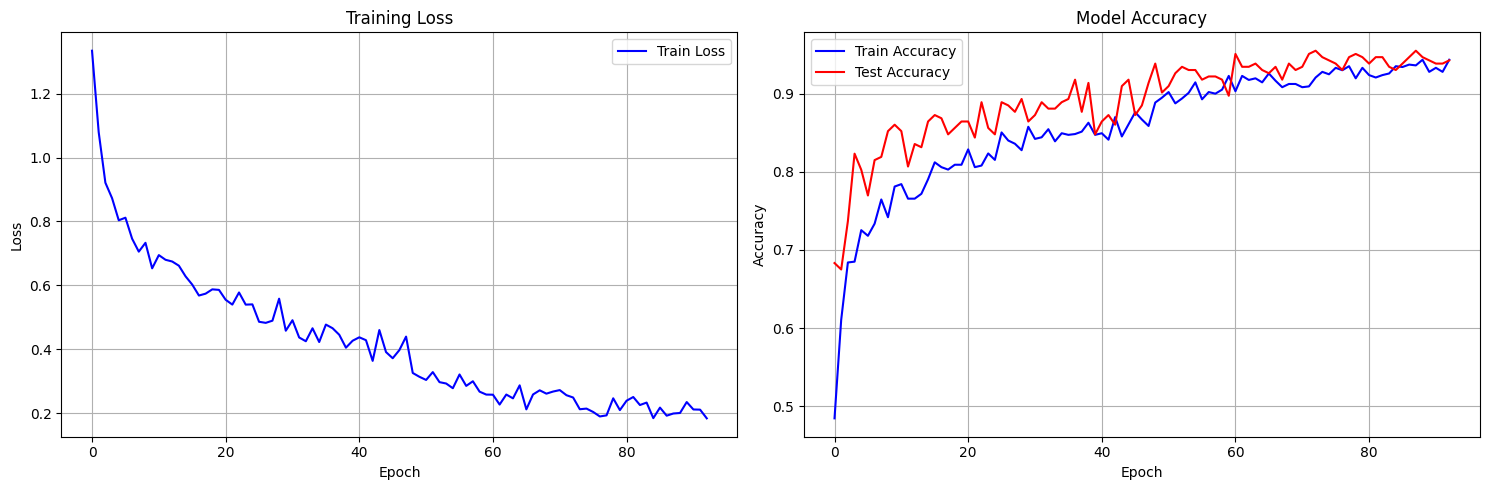

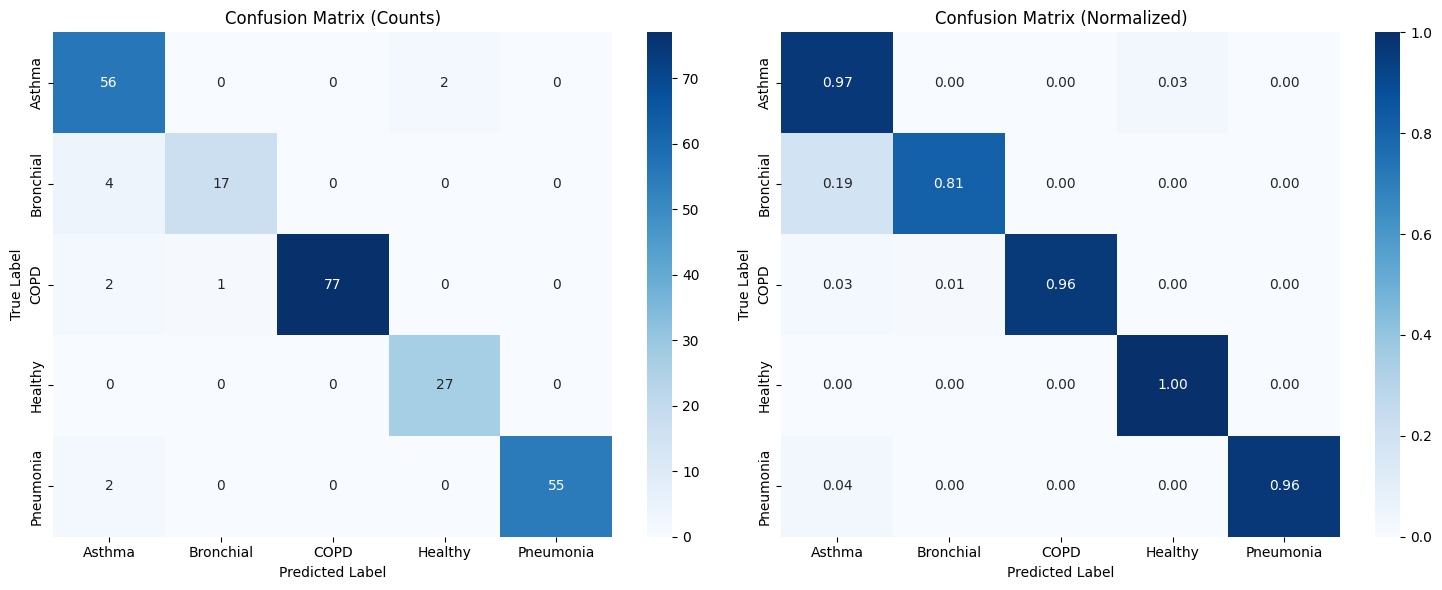


TRAINING COMPLETED SUCCESSFULLY
Best Test Accuracy: 0.9547
Model saved as: best_respiratory_model.pth
Training plots saved as: training_history.png, confusion_matrix.png

Running cross-validation...
Loading dataset from: Asthma Detection Dataset Version 2
Processing Bronchial folder...
Found 104 audio files in Bronchial
Processing asthma folder...
Found 288 audio files in asthma
Processing copd folder...
Found 401 audio files in copd
Processing healthy folder...
Found 133 audio files in healthy
Processing pneumonia folder...
Found 285 audio files in pneumonia

RESPIRATORY SOUND DATASET - LOADING REPORT
Dataset Path: Asthma Detection Dataset Version 2
Total Audio Files: 1211
Target Sample Rate: 16000 Hz
Target Duration: 5.0 seconds

Class Distribution:
  Bronchial   :  104 files (  8.6%)
  Asthma      :  288 files ( 23.8%)
  COPD        :  401 files ( 33.1%)
  Healthy     :  133 files ( 11.0%)
  Pneumonia   :  285 files ( 23.5%)

Class Imbalance Ratio: 3.86
Starting 5-fold cross-valida

In [6]:
# --- Complete Multi-Class Respiratory Sound Classification System --- #
import os
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as GeoDataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')


# ==================================================================
# 1. UPDATED DATASET LOADER
# ==================================================================
class RespiratoryDatasetLoader:
    def __init__(self, dataset_path, target_sr=16000, segment_duration=5.0):
        self.dataset_path = Path(dataset_path)
        self.target_sr = target_sr
        self.segment_duration = segment_duration
        self.target_samples = int(segment_duration * target_sr)
        self.audio_files = []
        self.labels = []
        self.metadata = []
        self.class_counts = {}
        self._load_dataset()
        self._print_dataset_info()

    def _load_dataset(self):
        class_folders = {
            'Bronchial': 'Bronchial',
            'asthma': 'Asthma',
            'copd': 'COPD',
            'healthy': 'Healthy',
            'pneumonia': 'Pneumonia'
        }
        print(f"Loading dataset from: {self.dataset_path}")
        for folder_name, class_label in class_folders.items():
            folder_path = self.dataset_path / folder_name
            if folder_path.exists():
                print(f"Processing {folder_name} folder...")
                audio_extensions = ['*.wav', '*.mp3', '*.flac', '*.m4a']
                audio_files = []
                for ext in audio_extensions:
                    audio_files.extend(list(folder_path.glob(ext)))
                    audio_files.extend(list(folder_path.rglob(ext)))
                audio_files = list(set(audio_files))
                print(f"Found {len(audio_files)} audio files in {folder_name}")
                for audio_file in audio_files:
                    self.audio_files.append(audio_file)
                    self.labels.append(class_label)
                    self.metadata.append({
                        'file_path': audio_file,
                        'folder': folder_name,
                        'class': class_label,
                        'filename': audio_file.name,
                        'file_size': audio_file.stat().st_size if audio_file.exists() else 0
                    })
                self.class_counts[class_label] = len(audio_files)
            else:
                print(f"Warning: Folder {folder_path} not found")
                self.class_counts[class_label] = 0

    def _print_dataset_info(self):
        print("\n" + "="*60)
        print("RESPIRATORY SOUND DATASET - LOADING REPORT")
        print("="*60)
        print(f"Dataset Path: {self.dataset_path}")
        print(f"Total Audio Files: {len(self.audio_files)}")
        print(f"Target Sample Rate: {self.target_sr} Hz")
        print(f"Target Duration: {self.segment_duration} seconds")

        print("\nClass Distribution:")
        total_files = len(self.audio_files)
        for class_name, count in self.class_counts.items():
            percentage = (count / total_files * 100) if total_files > 0 else 0
            print(f"  {class_name:12}: {count:4d} files ({percentage:5.1f}%)")

        if total_files > 0:
            counts_with_data = [c for c in self.class_counts.values() if c > 0]
            if counts_with_data:
                max_count = max(counts_with_data)
                min_count = min(counts_with_data)
                if max_count > 0 and min_count > 0:
                    imbalance_ratio = max_count / min_count
                    print(f"\nClass Imbalance Ratio: {imbalance_ratio:.2f}")
                    if imbalance_ratio > 3:
                        print("Warning: Significant class imbalance detected!")

    def load_audio(self, file_path):
        try:
            audio, sr = librosa.load(file_path, sr=self.target_sr)
            if len(audio) > self.target_samples:
                start = (len(audio) - self.target_samples) // 2
                audio = audio[start:start + self.target_samples]
            else:
                padding = self.target_samples - len(audio)
                audio = np.pad(audio, (0, padding), mode='constant')
            if np.max(np.abs(audio)) > 0:
                audio = audio / np.max(np.abs(audio))
            return audio, self.target_sr
        except Exception as e:
            print(f"Error loading {file_path}: {str(e)}")
            return None, None

    def extract_comprehensive_features(self, audio, sr):
        try:
            mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
            mfcc_delta = librosa.feature.delta(mfcc)
            mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

            spectral_centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
            spectral_rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)
            spectral_contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
            spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)

            zero_crossing_rate = librosa.feature.zero_crossing_rate(audio)

            chroma = librosa.feature.chroma_stft(y=audio, sr=sr)

            mel_spectrogram = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=13)
            mel_spectrogram = librosa.power_to_db(mel_spectrogram, ref=np.max)

            rms = librosa.feature.rms(y=audio)

            features = np.vstack([
                mfcc,
                mfcc_delta,
                mfcc_delta2,
                spectral_centroid,
                spectral_rolloff,
                spectral_contrast,
                spectral_bandwidth,
                zero_crossing_rate,
                chroma,
                mel_spectrogram,
                rms
            ])

            return features
        except Exception as e:
            print(f"Error extracting features: {str(e)}")
            return np.random.randn(76, 100)

    def get_sample(self, idx):
        if idx >= len(self.audio_files):
            return None
        file_path = self.audio_files[idx]
        label = self.labels[idx]
        metadata = self.metadata[idx]
        audio, sr = self.load_audio(file_path)
        if audio is None:
            return None
        features = self.extract_comprehensive_features(audio, sr)
        return {
            'audio': audio,
            'features': features,
            'label': label,
            'file_path': str(file_path),
            'metadata': metadata,
            'sample_rate': sr
        }

    def create_detailed_report(self):
        print("\n" + "="*60)
        print("DETAILED DATASET ANALYSIS")
        print("="*60)
        sample_size = min(20, len(self.audio_files))
        if sample_size == 0:
            print("No audio files to analyze!")
            return {'total_files': 0}
        sample_indices = np.random.choice(len(self.audio_files), sample_size, replace=False)
        durations = []
        file_sizes = []
        feature_shapes = []
        print("Analyzing sample files...")
        for idx in sample_indices:
            sample = self.get_sample(idx)
            if sample is not None:
                durations.append(len(sample['audio']) / sample['sample_rate'])
                file_sizes.append(sample['metadata']['file_size'])
                feature_shapes.append(sample['features'].shape)
        if durations:
            print(f"\nAudio Analysis (based on {len(durations)} samples):")
            print(f"  Average duration: {np.mean(durations):.2f} ± {np.std(durations):.2f} seconds")
            print(f"  Duration range: {np.min(durations):.2f} - {np.max(durations):.2f} seconds")
            print(f"\nFile Size Analysis:")
            avg_size_mb = np.mean(file_sizes) / (1024*1024)
            print(f"  Average file size: {avg_size_mb:.2f} MB")
            print(f"\nFeature Analysis:")
            if feature_shapes:
                avg_shape = np.mean(feature_shapes, axis=0)
                print(f"  Feature matrix shape: {avg_shape}")
                print(f"  Total features per sample: {avg_shape[0]:.0f}")
                print(f"  Time frames per sample: {avg_shape[1]:.0f}")
        return {
            'total_files': len(self.audio_files),
            'class_distribution': self.class_counts,
            'avg_duration': np.mean(durations) if durations else 0,
            'avg_file_size_mb': np.mean(file_sizes) / (1024*1024) if file_sizes else 0,
            'feature_dimensions': avg_shape if feature_shapes else None
        }


# ==================================================================
# 2. GRAPH CONSTRUCTION UTILITIES
# ==================================================================
class FeatureToGraphConverter:
    def __init__(self, k_neighbors=5):
        self.k_neighbors = k_neighbors

    def features_to_graph(self, features, label=None):
        features = features.T  # shape: (n_time_frames, n_features)
        edge_index = self._create_knn_graph(features)
        x = torch.FloatTensor(features)
        edge_index = torch.LongTensor(edge_index)
        if label is not None:
            data = Data(x=x, edge_index=edge_index, y=torch.LongTensor([label]))
        else:
            data = Data(x=x, edge_index=edge_index)
        return data

    def _create_knn_graph(self, features):
        n_nodes = features.shape[0]
        distances = np.linalg.norm(features[:, np.newaxis] - features[np.newaxis, :], axis=2)
        edges = []
        for i in range(n_nodes):
            neighbors = np.argsort(distances[i])[1:self.k_neighbors+1]
            for neighbor in neighbors:
                edges.append([i, neighbor])
                edges.append([neighbor, i])  # undirected
        if edges:
            edges = list(set([tuple(edge) for edge in edges]))
            edges = np.array(edges).T
        else:
            edges = np.array([[0], [0]])
        return edges


# ==================================================================
# 3. GRAPH DATASET CLASS
# ==================================================================
class GraphRespiratoryDataset(Dataset):
    def __init__(self, respiratory_dataset, indices=None):
        self.respiratory_dataset = respiratory_dataset
        self.indices = indices if indices is not None else list(range(len(respiratory_dataset.audio_files)))
        self.graph_converter = FeatureToGraphConverter()
        self.label_encoder = LabelEncoder()
        all_labels = [respiratory_dataset.labels[i] for i in self.indices]
        unique_labels = sorted(list(set(all_labels)))
        self.label_encoder.fit(unique_labels)
        print(f"Graph dataset size: {len(self.indices)} samples")
        print(f"Classes: {list(self.label_encoder.classes_)}")

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        sample = self.respiratory_dataset.get_sample(real_idx)
        if sample is None:
            dummy_features = np.random.randn(76, 100)
            return self.graph_converter.features_to_graph(dummy_features, 0)
        label_encoded = self.label_encoder.transform([sample['label']])[0]
        graph = self.graph_converter.features_to_graph(sample['features'], label_encoded)
        return graph


# ==================================================================
# 5. UPDATED GRAPH NEURAL NETWORK FOR MULTI-CLASS
# ==================================================================
class MultiClassRespiratoryGNN(nn.Module):
    def __init__(self, input_dim=76, hidden_dim=128, num_classes=5, dropout=0.5):
        super(MultiClassRespiratoryGNN, self).__init__()
        self.num_classes = num_classes
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.conv4 = GCNConv(hidden_dim, hidden_dim // 2)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.bn3 = nn.BatchNorm1d(hidden_dim)
        self.bn4 = nn.BatchNorm1d(hidden_dim // 2)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim // 2, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(dropout * 0.7),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, num_classes)
        )

    def forward(self, x, edge_index, batch):
        x1 = self.conv1(x, edge_index)
        x1 = self.bn1(x1)
        x1 = F.relu(x1)
        x1 = self.dropout(x1)
        x2 = self.conv2(x1, edge_index)
        x2 = self.bn2(x2)
        x2 = F.relu(x2)
        x2 = self.dropout(x2) + x1
        x3 = self.conv3(x2, edge_index)
        x3 = self.bn3(x3)
        x3 = F.relu(x3)
        x3 = self.dropout(x3) + x2
        x4 = self.conv4(x3, edge_index)
        x4 = self.bn4(x4)
        x4 = F.relu(x4)
        x = global_mean_pool(x4, batch)
        x = self.classifier(x)
        return F.log_softmax(x, dim=1)


# ==================================================================
# 6. ENHANCED TRAINING PIPELINE
# ==================================================================
class MultiClassTrainingPipeline:
    def __init__(self, dataset_path, device=None):
        self.device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"Using device: {self.device}")
        self.respiratory_dataset = RespiratoryDatasetLoader(dataset_path)
        self.dataset_report = self.respiratory_dataset.create_detailed_report()
        if len(self.respiratory_dataset.audio_files) == 0:
            raise ValueError("No audio files found in the dataset!")

        indices = list(range(len(self.respiratory_dataset.audio_files)))
        labels = [self.respiratory_dataset.labels[i] for i in indices]
        unique_labels = list(set(labels))
        stratify = labels if len(unique_labels) > 1 else None
        if stratify is None:
            print("Warning: Only one class found, cannot stratify split")

        self.train_indices, self.test_indices = train_test_split(
            indices, test_size=0.2, random_state=42, stratify=stratify
        )

        print(f"Train samples: {len(self.train_indices)}")
        print(f"Test samples: {len(self.test_indices)}")

        self.train_dataset = GraphRespiratoryDataset(self.respiratory_dataset, self.train_indices)
        self.test_dataset = GraphRespiratoryDataset(self.respiratory_dataset, self.test_indices)

        self.model = None
        self.optimizer = None
        self.scheduler = None
        self.criterion = nn.NLLLoss()

    def setup_model(self, hidden_dim=128, dropout=0.5):
        num_classes = len(set(self.respiratory_dataset.labels))
        input_dim = 76
        self.model = MultiClassRespiratoryGNN(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            num_classes=num_classes,
            dropout=dropout
        )
        self.model.to(self.device)
        self.optimizer = torch.optim.AdamW(
            self.model.parameters(),
            lr=0.001,
            weight_decay=1e-4
        )
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='max', factor=0.5, patience=10
        )
        total_params = sum(p.numel() for p in self.model.parameters())
        trainable_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        print(f"Model initialized with {total_params:,} total parameters")
        print(f"Trainable parameters: {trainable_params:,}")

    def train_epoch(self, dataloader):
        self.model.train()
        total_loss = 0
        correct = 0
        total = 0
        for batch in dataloader:
            batch = batch.to(self.device)
            self.optimizer.zero_grad()
            output = self.model(batch.x, batch.edge_index, batch.batch)
            loss = self.criterion(output, batch.y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()
            total_loss += loss.item()
            pred = output.argmax(dim=1)
            correct += (pred == batch.y).sum().item()
            total += batch.y.size(0)
        avg_loss = total_loss / len(dataloader)
        accuracy = correct / total
        return avg_loss, accuracy

    def evaluate(self, dataloader):
        self.model.eval()
        correct = 0
        total = 0
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for batch in dataloader:
                batch = batch.to(self.device)
                output = self.model(batch.x, batch.edge_index, batch.batch)
                pred = output.argmax(dim=1)
                correct += (pred == batch.y).sum().item()
                total += batch.y.size(0)
                all_preds.extend(pred.cpu().numpy())
                all_labels.extend(batch.y.cpu().numpy())
        accuracy = correct / total
        return accuracy, all_preds, all_labels

    def train_model(self, epochs=100, batch_size=16):
        if self.model is None:
            self.setup_model()
        train_loader = GeoDataLoader(self.train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = GeoDataLoader(self.test_dataset, batch_size=batch_size, shuffle=False)

        history = {
            'train_losses': [],
            'train_accuracies': [],
            'test_accuracies': [],
            'learning_rates': [],
            'final_predictions': None,
            'final_labels': None,
            'best_accuracy': 0,
            'classification_report': None
        }

        best_test_acc = 0
        patience = 20
        patience_counter = 0

        print(f"Starting training for {epochs} epochs...")
        print(f"Batch size: {batch_size}")
        print(f"Learning rate: {self.optimizer.param_groups[0]['lr']}")

        for epoch in range(epochs):
            train_loss, train_acc = self.train_epoch(train_loader)
            history['train_losses'].append(train_loss)
            history['train_accuracies'].append(train_acc)
            history['learning_rates'].append(self.optimizer.param_groups[0]['lr'])
            test_acc, test_preds, test_labels = self.evaluate(test_loader)
            history['test_accuracies'].append(test_acc)
            self.scheduler.step(test_acc)
            if test_acc > best_test_acc:
                best_test_acc = test_acc
                patience_counter = 0
                history['final_predictions'] = test_preds
                history['final_labels'] = test_labels
                torch.save({
                    'model_state_dict': self.model.state_dict(),
                    'optimizer_state_dict': self.optimizer.state_dict(),
                    'label_encoder': self.train_dataset.label_encoder,
                    'epoch': epoch,
                    'test_accuracy': test_acc
                }, 'best_respiratory_model.pth')
            else:
                patience_counter += 1
            if epoch % 10 == 0 or epoch == epochs - 1:
                print(f"Epoch {epoch:3d}: Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}, LR: {self.optimizer.param_groups[0]['lr']:.6f}")
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

        history['best_accuracy'] = best_test_acc
        print(f"\nTraining completed!")
        print(f"Best Test Accuracy: {best_test_acc:.4f}")

        class_names = self.train_dataset.label_encoder.classes_
        if history['final_labels'] is not None:
            report = classification_report(
                history['final_labels'], history['final_predictions'],
                target_names=class_names,
                output_dict=True
            )
            history['classification_report'] = report

            print(f"\nDetailed Classification Report:")
            print("-" * 50)
            for class_name in class_names:
                if class_name in report:
                    metrics = report[class_name]
                    print(f"{class_name:12}: Precision={metrics['precision']:.3f}, Recall={metrics['recall']:.3f}, F1={metrics['f1-score']:.3f}")

            print(f"\nOverall Performance:")
            print(f"Accuracy: {report['accuracy']:.3f}")
            print(f"Macro Avg F1: {report['macro avg']['f1-score']:.3f}")
            print(f"Weighted Avg F1: {report['weighted avg']['f1-score']:.3f}")

        return history

    def plot_training_history(self, history):
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        axes[0].plot(history['train_losses'], label='Train Loss', color='blue')
        axes[0].set_title('Training Loss')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Loss')
        axes[0].legend()
        axes[0].grid(True)
        axes[1].plot(history['train_accuracies'], label='Train Accuracy', color='blue')
        axes[1].plot(history['test_accuracies'], label='Test Accuracy', color='red')
        axes[1].set_title('Model Accuracy')
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Accuracy')
        axes[1].legend()
        axes[1].grid(True)
        plt.tight_layout()
        plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
        plt.show()

    def plot_confusion_matrix(self, history):
        if history['final_labels'] is None or history['final_predictions'] is None:
            print("No labels or predictions available for confusion matrix")
            return
        y_true = history['final_labels']
        y_pred = history['final_predictions']
        class_names = self.train_dataset.label_encoder.classes_
        cm = confusion_matrix(y_true, y_pred)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax1)
        ax1.set_title('Confusion Matrix (Counts)')
        ax1.set_xlabel('Predicted Label')
        ax1.set_ylabel('True Label')
        cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax2)
        ax2.set_title('Confusion Matrix (Normalized)')
        ax2.set_xlabel('Predicted Label')
        ax2.set_ylabel('True Label')
        plt.tight_layout()
        plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
        plt.show()
        return fig

    def predict_single_file(self, audio_path, model_path='best_respiratory_model.pth'):
        try:
            checkpoint = torch.load(model_path, map_location=self.device)
            self.model.load_state_dict(checkpoint['model_state_dict'])
            label_encoder = checkpoint['label_encoder']
            self.model.eval()
            audio, sr = librosa.load(audio_path, sr=self.respiratory_dataset.target_sr)
            target_samples = self.respiratory_dataset.target_samples
            if len(audio) > target_samples:
                start = (len(audio) - target_samples) // 2
                audio = audio[start:start + target_samples]
            else:
                padding = target_samples - len(audio)
                audio = np.pad(audio, (0, padding), mode='constant')
            if np.max(np.abs(audio)) > 0:
                audio = audio / np.max(np.abs(audio))
            features = self.respiratory_dataset.extract_comprehensive_features(audio, sr)
            converter = FeatureToGraphConverter()
            graph = converter.features_to_graph(features)
            graph = graph.to(self.device)
            batch = Batch.from_data_list([graph])
            with torch.no_grad():
                output = self.model(batch.x, batch.edge_index, batch.batch)
                probabilities = torch.exp(output).cpu().numpy()[0]
                predicted_class_idx = np.argmax(probabilities)
                predicted_class = label_encoder.classes_[predicted_class_idx]
                confidence = probabilities[predicted_class_idx]
            results = {
                'predicted_class': predicted_class,
                'confidence': confidence,
                'all_probabilities': {
                    label_encoder.classes_[i]: prob for i, prob in enumerate(probabilities)
                }
            }
            return results
        except Exception as e:
            print(f"Error predicting file {audio_path}: {str(e)}")
            return None

    def create_comprehensive_report(self, history):
        report = {
            'dataset_info': self.dataset_report,
            'training_info': {
                'total_epochs': len(history['train_losses']),
                'best_accuracy': history['best_accuracy'],
                'final_train_accuracy': history['train_accuracies'][-1],
                'final_test_accuracy': history['test_accuracies'][-1],
            },
            'model_info': {
                'total_parameters': sum(p.numel() for p in self.model.parameters()),
                'trainable_parameters': sum(p.numel() for p in self.model.parameters() if p.requires_grad),
                'device': str(self.device)
            },
            'classification_report': history['classification_report']
        }
        return report


# ==================================================================
# 7. CROSS-VALIDATION PIPELINE
# ==================================================================
class CrossValidationPipeline:
    def __init__(self, dataset_path, k_folds=5):
        self.dataset_path = dataset_path
        self.k_folds = k_folds
        self.respiratory_dataset = RespiratoryDatasetLoader(dataset_path)
        if len(self.respiratory_dataset.audio_files) == 0:
            raise ValueError("No audio files found in the dataset!")

    def run_cross_validation(self, epochs=50, batch_size=16):
        indices = list(range(len(self.respiratory_dataset.audio_files)))
        labels = [self.respiratory_dataset.labels[i] for i in indices]
        skf = StratifiedKFold(n_splits=self.k_folds, shuffle=True, random_state=42)
        cv_results = {
            'fold_accuracies': [],
            'fold_reports': [],
            'mean_accuracy': 0,
            'std_accuracy': 0,
            'all_predictions': [],
            'all_labels': []
        }
        print(f"Starting {self.k_folds}-fold cross-validation...")
        for fold, (train_idx, val_idx) in enumerate(skf.split(indices, labels)):
            print(f"\nFold {fold + 1}/{self.k_folds}")
            print("-" * 40)
            train_dataset = GraphRespiratoryDataset(self.respiratory_dataset, train_idx)
            val_dataset = GraphRespiratoryDataset(self.respiratory_dataset, val_idx)
            train_loader = GeoDataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            val_loader = GeoDataLoader(val_dataset, batch_size=batch_size, shuffle=False)
            device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
            num_classes = len(set(self.respiratory_dataset.labels))
            model = MultiClassRespiratoryGNN(
                input_dim=76, hidden_dim=128, num_classes=num_classes, dropout=0.5
            ).to(device)
            optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
            criterion = nn.NLLLoss()
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='max', factor=0.5, patience=5
            )
            best_val_acc = 0
            patience_counter = 0
            for epoch in range(epochs):
                model.train()
                for batch in train_loader:
                    batch = batch.to(device)
                    optimizer.zero_grad()
                    output = model(batch.x, batch.edge_index, batch.batch)
                    loss = criterion(output, batch.y)
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                model.eval()
                correct = 0
                total = 0
                val_preds = []
                val_labels = []
                with torch.no_grad():
                    for batch in val_loader:
                        batch = batch.to(device)
                        output = model(batch.x, batch.edge_index, batch.batch)
                        pred = output.argmax(dim=1)
                        correct += (pred == batch.y).sum().item()
                        total += batch.y.size(0)
                        val_preds.extend(pred.cpu().numpy())
                        val_labels.extend(batch.y.cpu().numpy())
                val_acc = correct / total
                scheduler.step(val_acc)
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_preds = val_preds.copy()
                    best_labels = val_labels.copy()
                    patience_counter = 0
                else:
                    patience_counter += 1
                if patience_counter >= 10:
                    break
                if epoch % 10 == 0:
                    print(f"  Epoch {epoch}: Val Acc = {val_acc:.4f}")
            cv_results['fold_accuracies'].append(best_val_acc)
            class_names = train_dataset.label_encoder.classes_
            fold_report = classification_report(
                best_labels, best_preds, target_names=class_names, output_dict=True
            )
            cv_results['fold_reports'].append(fold_report)
            cv_results['all_predictions'].extend(best_preds)
            cv_results['all_labels'].extend(best_labels)
            print(f"  Fold {fold + 1} Best Accuracy: {best_val_acc:.4f}")
        cv_results['mean_accuracy'] = np.mean(cv_results['fold_accuracies'])
        cv_results['std_accuracy'] = np.std(cv_results['fold_accuracies'])
        print(f"\nCross-Validation Results:")
        print(f"Mean Accuracy: {cv_results['mean_accuracy']:.4f} ± {cv_results['std_accuracy']:.4f}")
        print(f"Fold Accuracies: {[f'{acc:.4f}' for acc in cv_results['fold_accuracies']]}")
        return cv_results


# ==================================================================
# 8. MAIN EXECUTION PIPELINE
# ==================================================================
def main_training_pipeline(dataset_path):
    try:
        print("="*60)
        print("MULTI-CLASS RESPIRATORY SOUND CLASSIFICATION")
        print("="*60)
        pipeline = MultiClassTrainingPipeline(dataset_path)
        history = pipeline.train_model(epochs=100, batch_size=16)
        pipeline.plot_training_history(history)
        pipeline.plot_confusion_matrix(history)
        report = pipeline.create_comprehensive_report(history)
        print("\n" + "="*60)
        print("TRAINING COMPLETED SUCCESSFULLY")
        print("="*60)
        print(f"Best Test Accuracy: {history['best_accuracy']:.4f}")
        print(f"Model saved as: best_respiratory_model.pth")
        print(f"Training plots saved as: training_history.png, confusion_matrix.png")
        return pipeline, history, report
    except Exception as e:
        print(f"Error in main pipeline: {str(e)}")
        import traceback
        traceback.print_exc()
        return None, None, None


def run_cross_validation(dataset_path):
    try:
        cv_pipeline = CrossValidationPipeline(dataset_path, k_folds=5)
        cv_results = cv_pipeline.run_cross_validation(epochs=50, batch_size=16)
        return cv_results
    except Exception as e:
        print(f"Error in cross-validation: {str(e)}")
        return None


# ==================================================================
# 9. USAGE EXAMPLE
# ==================================================================
if __name__ == "__main__":
    DATASET_PATH = "Asthma Detection Dataset Version 2"
    print("Choose an option:")
    print("1. Train model with train/test split")
    print("2. Run k-fold cross-validation")
    print("3. Both")
    choice = input("Enter choice (1/2/3): ").strip()
    if choice in ['1', '3']:
        print("\nRunning main training pipeline...")
        pipeline, history, report = main_training_pipeline(DATASET_PATH)
    if choice in ['2', '3']:
        print("\nRunning cross-validation...")
        cv_results = run_cross_validation(DATASET_PATH)
        if cv_results is not None:
            print(f"Cross-validation completed with mean accuracy: {cv_results['mean_accuracy']:.4f}")


# ==================================================================
# 10. UTILITY FUNCTIONS
# ==================================================================
def load_and_predict(model_path, audio_path, dataset_path):
    try:
        dataset_loader = RespiratoryDatasetLoader(dataset_path)
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        checkpoint = torch.load(model_path, map_location=device)
        num_classes = len(checkpoint['label_encoder'].classes_)
        model = MultiClassRespiratoryGNN(
            input_dim=76,
            hidden_dim=128,
            num_classes=num_classes,
            dropout=0.5
        )
        model.load_state_dict(checkpoint['model_state_dict'])
        model.to(device)
        model.eval()
        audio, sr = librosa.load(audio_path, sr=dataset_loader.target_sr)
        target_samples = dataset_loader.target_samples
        if len(audio) > target_samples:
            start = (len(audio) - target_samples) // 2
            audio = audio[start:start + target_samples]
        else:
            padding = target_samples - len(audio)
            audio = np.pad(audio, (0, padding), mode='constant')
        if np.max(np.abs(audio)) > 0:
            audio = audio / np.max(np.abs(audio))
        features = dataset_loader.extract_comprehensive_features(audio, sr)
        converter = FeatureToGraphConverter()
        graph = converter.features_to_graph(features)
        graph = graph.to(device)
        batch = Batch.from_data_list([graph])
        with torch.no_grad():
            output = model(batch.x, batch.edge_index, batch.batch)
            probabilities = torch.exp(output).cpu().numpy()[0]
            predicted_class_idx = np.argmax(probabilities)
            predicted_class = checkpoint['label_encoder'].classes_[predicted_class_idx]
            confidence = probabilities[predicted_class_idx]
        return {
            'predicted_class': predicted_class,
            'confidence': confidence,
            'all_probabilities': {
                checkpoint['label_encoder'].classes_[i]: prob for i, prob in enumerate(probabilities)
            }
        }
    except Exception as e:
        print(f"Error in prediction: {str(e)}")
        return None


def analyze_dataset_only(dataset_path):
    try:
        loader = RespiratoryDatasetLoader(dataset_path)
        report = loader.create_detailed_report()
        return report
    except Exception as e:
        print(f"Error analyzing dataset: {str(e)}")
        return None


In [27]:
import torch
from sklearn.preprocessing._label import LabelEncoder

torch.serialization.add_safe_globals([LabelEncoder])
checkpoint = torch.load('best_respiratory_model.pth', weights_only=False)


In [1]:
import torch
import pickle
import json
import numpy
from pathlib import Path
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_mean_pool
import torch.nn as nn
import librosa
import warnings
warnings.filterwarnings('ignore')

class FeatureToGraphConverter:
    def __init__(self, k_neighbors=5):
        self.k_neighbors = k_neighbors

    def features_to_graph(self, features, label=None):
        features = features.T
        edge_index = self._create_knn_graph(features)
        x = torch.FloatTensor(features)
        edge_index = torch.LongTensor(edge_index)
        if label is not None:
            data = Data(x=x, edge_index=edge_index, y=torch.LongTensor([label]))
        else:
            data = Data(x=x, edge_index=edge_index)
        return data

    def _create_knn_graph(self, features):
        n_nodes = features.shape[0]
        if n_nodes <= 1:
            return numpy.array([[0], [0]])
        distances = numpy.linalg.norm(features[:, numpy.newaxis] - features[numpy.newaxis, :], axis=2)
        edges = []
        for i in range(n_nodes):
            k_actual = min(self.k_neighbors, n_nodes - 1)
            neighbors = numpy.argsort(distances[i])[1:k_actual + 1]
            for neighbor in neighbors:
                edges.append([i, neighbor])
                edges.append([neighbor, i])
        if edges:
            edges = list(set([tuple(edge) for edge in edges]))
            edges = numpy.array(edges).T
        else:
            edges = numpy.array([[0], [0]])
        return edges

class MultiClassRespiratoryGNN(nn.Module):
    def __init__(self, input_dim=76, hidden_dim=128, num_classes=5, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.conv4 = GCNConv(hidden_dim, hidden_dim // 2)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.bn3 = nn.BatchNorm1d(hidden_dim)
        self.bn4 = nn.BatchNorm1d(hidden_dim // 2)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim // 2, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(dropout * 0.7),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            nn.Dropout(dropout * 0.5),
            nn.Linear(32, num_classes)
        )

    def forward(self, x, edge_index, batch):
        x1 = F.relu(self.bn1(self.conv1(x, edge_index)))
        x1 = self.dropout(x1)
        x2 = F.relu(self.bn2(self.conv2(x1, edge_index)))
        x2 = self.dropout(x2) + x1
        x3 = F.relu(self.bn3(self.conv3(x2, edge_index)))
        x3 = self.dropout(x3) + x2
        x4 = F.relu(self.bn4(self.conv4(x3, edge_index)))
        x = global_mean_pool(x4, batch)
        x = self.classifier(x)
        return F.log_softmax(x, dim=1)

class SimpleRespiratoryPredictor:
    def __init__(self, model_path):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model_path = Path(model_path)
        if not self.model_path.exists():
            raise FileNotFoundError(f"Model path not found: {model_path}")
        self._load_model()
        print(f"Model loaded successfully!")
        print(f"Device: {self.device}")
        print(f"Classes: {', '.join(self.label_encoder.classes_)}")
        print(f"Ready to predict audio files")

    def _load_model(self):
        try:
            metadata_path = self.model_path / 'metadata.json'
            if not metadata_path.exists():
                raise FileNotFoundError(f"metadata.json not found in {self.model_path}")
            with open(metadata_path, 'r') as f:
                self.metadata = json.load(f)
            label_path = self.model_path / 'label_encoder.pkl'
            if not label_path.exists():
                raise FileNotFoundError(f"label_encoder.pkl not found in {self.model_path}")
            with open(label_path, 'rb') as f:
                self.label_encoder = pickle.load(f)
            self.graph_converter = FeatureToGraphConverter()
            model_path_file = self.model_path / 'model.pth'
            if not model_path_file.exists():
                raise FileNotFoundError(f"model.pth not found in {self.model_path}")
            model_config = self.metadata['model_config']
            self.model = MultiClassRespiratoryGNN(**model_config)

            # Add safe global for numpy._core.multiarray.scalar as required by PyTorch 2.6+
            import numpy
            torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])

            checkpoint = torch.load(model_path_file, map_location=self.device, weights_only=False)
            self.model.load_state_dict(checkpoint['model_state_dict'])
            self.model.to(self.device)
            self.model.eval()
        except Exception as e:
            print(f"Error loading model: {e}")
            raise

    def predict_audio_file(self, audio_file_path):
        print(f"\nAnalyzing: {Path(audio_file_path).name}")
        print("-" * 50)
        if not Path(audio_file_path).exists():
            print(f"Error: Audio file not found: {audio_file_path}")
            return None
        try:
            audio, sr = self._preprocess_audio(audio_file_path)
            if audio is None:
                return None
            features = self._extract_features(audio, sr)
            if features is None:
                return None
            prediction_result = self._make_prediction(features)
            self._display_prediction(prediction_result, audio_file_path)
            return prediction_result
        except Exception as e:
            print(f"Error processing audio file: {e}")
            return None

    def _preprocess_audio(self, audio_file_path):
        try:
            target_sr = 16000
            duration = 5.0
            target_samples = int(duration * target_sr)
            print(f"Loading audio file...")
            audio, sr = librosa.load(audio_file_path, sr=target_sr)
            if len(audio) == 0:
                print("Error: Empty audio file")
                return None, None
            print(f"Original audio: {len(audio)/target_sr:.2f}s")
            if len(audio) > target_samples:
                start = (len(audio) - target_samples) // 2
                audio = audio[start:start + target_samples]
                print(f"Audio trimmed to {duration} seconds")
            elif len(audio) < target_samples:
                padding = target_samples - len(audio)
                audio = numpy.pad(audio, (0, padding), mode='constant')
                print(f"Audio padded to {duration} seconds")
            if numpy.max(numpy.abs(audio)) > 0:
                audio = audio / numpy.max(numpy.abs(audio))
            else:
                print("Warning: Silent audio detected")
            print(f"Audio processed: {len(audio)/sr:.1f}s at {sr}Hz")
            return audio, sr
        except Exception as e:
            print(f"Error loading audio: {e}")
            return None, None

    def _extract_features(self, audio, sr):
        try:
            print("Extracting audio features...")
            mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
            mfcc_delta = librosa.feature.delta(mfcc)
            mfcc_delta2 = librosa.feature.delta(mfcc, order=2)
            spectral_centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
            spectral_rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)
            spectral_contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
            spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)
            zero_crossing_rate = librosa.feature.zero_crossing_rate(audio)
            rms = librosa.feature.rms(y=audio)
            chroma = librosa.feature.chroma_stft(y=audio, sr=sr)
            mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=13)
            mel_spec = librosa.power_to_db(mel_spec, ref=numpy.max)
            features = numpy.vstack([
                mfcc,
                mfcc_delta,
                mfcc_delta2,
                spectral_centroid,
                spectral_rolloff,
                spectral_contrast,
                spectral_bandwidth,
                zero_crossing_rate,
                chroma,
                mel_spec,
                rms
            ])
            print(f"Features extracted: {features.shape[0]} features x {features.shape[1]} time frames")
            if features.shape[0] != 76:
                print(f"Warning: Expected 76 features, got {features.shape[0]}")
            return features
        except Exception as e:
            print(f"Error extracting features: {e}")
            return None

    def _make_prediction(self, features):
        try:
            print("Making prediction...")
            graph = self.graph_converter.features_to_graph(features)
            graph = graph.to(self.device)
            with torch.no_grad():
                batch = torch.zeros(graph.x.shape[0], dtype=torch.long, device=self.device)
                output = self.model(graph.x, graph.edge_index, batch)
                probabilities = torch.exp(output[0])
                predicted_idx = output.argmax(dim=1).item()
                confidence = probabilities.max().item()
                predicted_class = self.label_encoder.inverse_transform([predicted_idx])[0]
            class_probabilities = {cls: float(probabilities[i]) for i, cls in enumerate(self.label_encoder.classes_)}
            sorted_probs = sorted(class_probabilities.items(), key=lambda x: x[1], reverse=True)
            result = {
                'prediction': predicted_class,
                'confidence': confidence,
                'all_probabilities': class_probabilities,
                'sorted_probabilities': sorted_probs
            }
            return result
        except Exception as e:
            print(f"Error making prediction: {e}")
            return None

    def _display_prediction(self, result, audio_file_path):
        if result is None:
            print("Prediction failed")
            return
        print(f"\nPREDICTION RESULTS")
        print("=" * 30)
        print(f"File: {Path(audio_file_path).name}")
        print(f"PREDICTED CONDITION: {result['prediction']}")
        print(f"CONFIDENCE: {result['confidence']:.1%}\n")
        print("All Class Probabilities:")
        print("-" * 25)
        for class_name, prob in result['sorted_probabilities']:
            bar_length = int(prob * 20)
            bar = "█" * bar_length + "░" * (20 - bar_length)
            print(f"{class_name:12} {prob:5.1%} |{bar}|")
        print()
        print("MEDICAL DISCLAIMER:")
        print("This prediction is for research purposes only.")
        print("Do NOT use for medical diagnosis or treatment decisions.")
        print("Always consult qualified healthcare professionals.")
        print("-" * 50)


In [2]:
if __name__ == "__main__":
    # Replace with your saved model folder containing metadata.json, model.pth, label_encoder.pkl
    model_folder = r"C:\Users\admin\Desktop\pro\saved_models\respiratory_model_20250904_002134"
    
    # Replace with the path of one audio file for prediction
    test_audio_file = r"C:\Users\admin\Desktop\pro\Asthma Detection Dataset Version 2\copd\P2COPDMc_10.wav"
    
    # Initialize predictor
    predictor = SimpleRespiratoryPredictor(model_folder)
    
    # Run prediction (this will print detailed info)
    result = predictor.predict_audio_file(test_audio_file)
    
    if result:
        print(f"\nFinal Prediction: {result['prediction']} with confidence {result['confidence']:.1%}")
    else:
        print("Prediction failed. Check audio file or model paths.")


Model loaded successfully!
Device: cpu
Classes: Asthma, Bronchial, COPD, Healthy, Pneumonia
Ready to predict audio files

Analyzing: P2COPDMc_10.wav
--------------------------------------------------
Loading audio file...
Original audio: 6.00s
Audio trimmed to 5.0 seconds
Audio processed: 5.0s at 16000Hz
Extracting audio features...
Features extracted: 76 features x 157 time frames
Making prediction...

PREDICTION RESULTS
File: P2COPDMc_10.wav
PREDICTED CONDITION: COPD
CONFIDENCE: 100.0%

All Class Probabilities:
-------------------------
COPD         100.0% |███████████████████░|
Pneumonia     0.0% |░░░░░░░░░░░░░░░░░░░░|
Asthma        0.0% |░░░░░░░░░░░░░░░░░░░░|
Bronchial     0.0% |░░░░░░░░░░░░░░░░░░░░|
Healthy       0.0% |░░░░░░░░░░░░░░░░░░░░|

MEDICAL DISCLAIMER:
This prediction is for research purposes only.
Do NOT use for medical diagnosis or treatment decisions.
Always consult qualified healthcare professionals.
--------------------------------------------------

Final Prediction